# a prototyping notebook for parallelization

In [1]:
import torch

from anemone.experiment import *
from anemone.transforms import *
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda')

In [2]:
import copy
precalcHankel0 =  BaseHankel(lambda x:x, 0, smp_per_decade=4,  device=device)
precalcHankel1 =  BaseHankel(lambda x:x, 1, smp_per_decade=4,  device=device)
precalcFourier =  BaseFourier(lambda x:x,   smp_per_decade=10, device=device)

def Hankel(func, order):
    if order==0:
        self = copy.deepcopy(precalcHankel0)
    elif order==1:
        self = copy.deepcopy(precalcHankel1)
    self.func = func
    self.F = self.func(self.lamda)
    return self

def Fourier(func):
    self = copy.deepcopy(precalcFourier)
    self.func = func
    self.F = self.func(self.lamda).T*torch.sqrt(self.lamda)
    return self

In [3]:
def colecole(rho_o, m, tau, c, omega):
    tmp = 1.+(1j*omega*tau)**c
    tmp = 1. - 1./tmp
    tmp = 1. - m*tmp
    rho = rho_o*tmp
    return rho

class IPForward:
    def __init__(self, source, receiver, times=tc.logspace(1e-5, 1e-2, 31)):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times, device=device)
        self.cpu_times = self.times.cpu()
        self.lgtimes = torch.log(self.times)

        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.r = precalcHankel1.range(self.rmin, self.rmax)[0].cpu()#
        self.sofr = torch.tensor(self.source.s_of_r(self.receiver, self.r.numpy()), dtype=torch.complex128, device=device)#
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=device)
        self.r.to(device)

    def forward(self):
        def frq_integrand(omega):
            omega = omega[None,:,None].to(device)
            self.sigma = 1./colecole(self.rho, self.m, self.tau, self.c, omega)
            def hankel_integrand(wave_length):
                lmb = wave_length[None, None, :].to(device)
                tmp_u0 = u0(omega, lmb)
                intg = (torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb))*lmb**2 / tmp_u0
                return torch.squeeze(intg/(1j*omega))
            hkl = Hankel(hankel_integrand, 1)
            
            r, hr = hkl.range(self.rmin, self.rmax)
            hr /= r[:,None,None]
            return hr.T@self.sofr
        f_t=Fourier(frq_integrand)
        t,dbdt = f_t.range(self.cpu_times[0], self.cpu_times[-1])
        return t, dbdt

    def __call__(self, rho, m, tau, c, thickness):
        self.rho   = torch.tensor(rho, dtype=torch.complex128, device=device)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128, device=device)[...,None,None]
        self.m     = torch.tensor(m, dtype=torch.complex128, device=device)[..., None,None]
        self.tau   = torch.tensor(tau, dtype=torch.complex128, device=device)[..., None,None]
        self.c     = torch.tensor(c, dtype=torch.complex128, device=device)[..., None,None]
        return self.forward()

In [5]:
lp = Loop.circle(6, z=20)
rx = Receiver(z=25)
times = np.logspace(-5,-2, 31)#.to(device)

In [14]:
n_forwards = np.logspace(0, np.log10(500), 12).astype(int)
t_forwards = np.zeros(n_forwards.shape)

from time import perf_counter as timer

fwr = IPForward(lp, rx, times)
for i_nf,nf in enumerate(n_forwards):
    rho = 1./(torch.tensor([0.1, 1, 0.1, 0.3, 10, 25])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:])
    thick = torch.tensor([40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    m     = torch.tensor([0.1]*6)[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    tau   = torch.tensor([0.1]*6)[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    c     = torch.tensor([0.1]*6)[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

    bt = timer()
    t1,dbdt1 = fwr(rho, m, tau, c, thick)
    t_forwards[i_nf] = (timer()-bt)
    print(i_nf, nf, t_forwards[i_nf]/nf)

C:\Users\au646858\AppData\Local\Temp\38\ipykernel_481196\139525829.py:42: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.rho   = torch.tensor(rho, dtype=torch.complex128, device=device)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\38\ipykernel_481196\139525829.py:43: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128, device=device)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\38\ipykernel_481196\139525829.py:44: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.m  

0 1 0.04259220000000141
1 1 0.0431100999999785
2 3 0.01328289999999773
3 5 0.010306080000003704
4 9 0.00877611111111302
5 16 0.001628300000000138
6 29 0.0011354206896547912
7 52 0.0009552153846154982
8 91 0.0008383978021978751
9 161 0.0006021322981365988
10 284 0.0005382362676056359
11 499 0.00046175851703404263


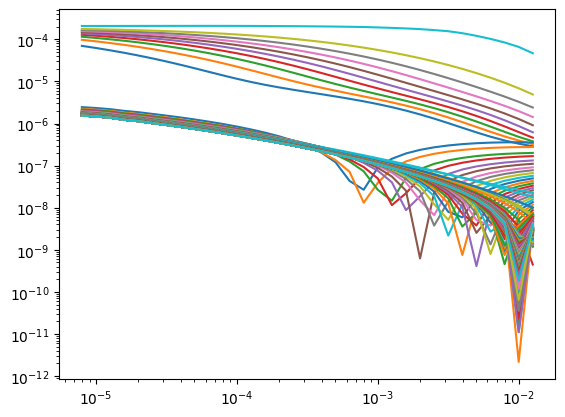

In [15]:
plt.figure()
plt.loglog(t1.cpu().numpy(), np.abs(dbdt1.cpu().numpy().real));

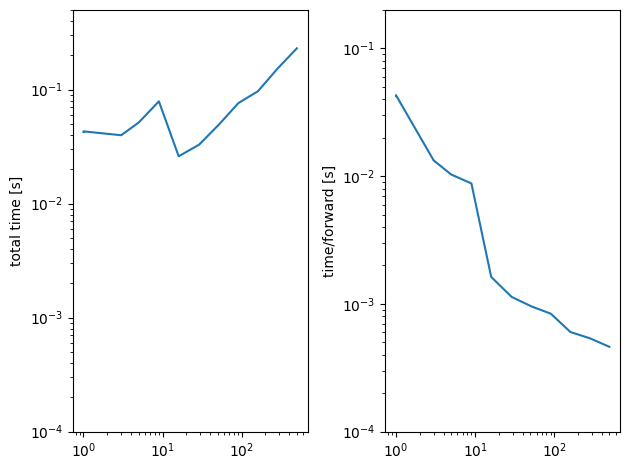

In [16]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(n_forwards, t_forwards);            axs[0].set_ylabel('total time [s]')
axs[1].loglog(n_forwards, t_forwards/n_forwards); axs[1].set_ylabel('time/forward [s]')
axs[0].set_ylim(0.0001, 0.5)
axs[1].set_ylim(0.0001, 0.2)
plt.tight_layout()